#Projeto integrador interdiciplinar


#Contexto basico do banco

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('history.csv')



In [3]:
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas\n")

Dimensões do dataset: 5634 linhas e 23 colunas



In [4]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5634 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   object 
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5634 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [6]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,5634.0,0.164714,0.370955,0.0,0.0000,0.000,0.00,1.00
MonthlyCharges,5634.0,64.609523,30.152186,18.4,35.1625,70.300,89.80,118.65
TotalCharges,5356.0,2271.883150,2253.784765,18.8,412.9000,1390.725,3729.75,8684.80
MonthlyIncome,5634.0,5104.879304,2839.230500,100.0,2693.7500,5079.500,7574.75,9993.00


#Dicionario de dados

variavel,
definição,
unidades,
tipagem.

#Observações importantes

tenure: está tipada como object, mas representa um período em meses. Se os valores forem numéricos, pode ser conveniente convertê-la para inteiro.

SeniorCitizen: normalmente utiliza 0 para indicar que o cliente não é idoso e 1 para indicar que é idoso, mas vale confirmar os valores da sua base.

MonthlyCharges, TotalCharges e MonthlyIncome: confirme a moeda utilizada. A tipagem float64 permite casas decimais, enquanto int64 representa números inteiros.

CustomerFeedback: a definição exata depende do conteúdo dessa coluna, que pode conter avaliações, comentários ou categorias.

Tipagem: mantive os tipos que você informou no Colab, sem alterar o banco de dados.

In [7]:
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure               object
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
CustomerFeedback     object
MonthlyIncome         int64
dtype: object


In [8]:
dicionario_dados = {
    "Variável": [
        "customerID",
        "gender",
        "SeniorCitizen",
        "Partner",
        "Dependents",
        "tenure",
        "PhoneService",
        "MultipleLines",
        "InternetService",
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies",
        "Contract",
        "PaperlessBilling",
        "PaymentMethod",
        "MonthlyCharges",
        "TotalCharges",
        "Churn",
        "CustomerFeedback",
        "MonthlyIncome"
    ],

    "Definição": [
        "Identificador único de cada cliente.",
        "Gênero do cliente.",
        "Indica se o cliente é idoso.",
        "Indica se o cliente possui cônjuge ou companheiro(a).",
        "Indica se o cliente possui dependentes.",
        "Tempo de permanência do cliente na empresa.",
        "Indica se o cliente possui serviço telefônico.",
        "Indica se o cliente possui múltiplas linhas telefônicas.",
        "Tipo de serviço de internet contratado.",
        "Indica se o cliente possui segurança online.",
        "Indica se o cliente possui backup online.",
        "Indica se o cliente possui proteção de dispositivos.",
        "Indica se o cliente possui suporte técnico.",
        "Indica se o cliente possui serviço de streaming de TV.",
        "Indica se o cliente possui serviço de streaming de filmes.",
        "Tipo de contrato firmado com a empresa.",
        "Indica se o cliente utiliza faturamento sem papel.",
        "Método de pagamento utilizado pelo cliente.",
        "Valor cobrado mensalmente pelos serviços.",
        "Valor total cobrado do cliente no período registrado.",
        "Indica se o cliente cancelou o serviço.",
        "Feedback ou avaliação fornecida pelo cliente.",
        "Renda mensal registrada para o cliente."
    ],

    "Unidade": [
        "Não se aplica",
        "Categoria",
        "Binária (0 ou 1)",
        "Sim/Não",
        "Sim/Não",
        "Meses",
        "Sim/Não",
        "Categoria",
        "Categoria",
        "Sim/Não/Não possui internet",
        "Sim/Não/Não possui internet",
        "Sim/Não/Não possui internet",
        "Sim/Não/Não possui internet",
        "Sim/Não/Não possui internet",
        "Sim/Não/Não possui internet",
        "Categoria",
        "Sim/Não",
        "Categoria",
        "Moeda",
        "Moeda",
        "Sim/Não",
        "Categoria ou texto",
        "Moeda"
    ],

    "Tipagem": [
        "object",
        "object",
        "int64",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "object",
        "float64",
        "float64",
        "object",
        "object",
        "int64"
    ]
}

In [9]:
# Criar o DataFrame do dicionário
df_dicionario = pd.DataFrame(dicionario_dados)

# Exibir a tabela completa no Google Colab
display(df_dicionario)

# Opcional: salvar o dicionário em um arquivo CSV
df_dicionario.to_csv(
    "dicionario_de_dados.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dicionário de dados criado e salvo em CSV!")

,Variável,Definição,Unidade,Tipagem
0,customerID,Identificador único de cada cliente.,Não se aplica,object
1,gender,Gênero do cliente.,Categoria,object
2,SeniorCitizen,Indica se o cliente é idoso.,Binária (0 ou 1),int64
3,Partner,Indica se o cliente possui cônjuge ou companhe...,Sim/Não,object
4,Dependents,Indica se o cliente possui dependentes.,Sim/Não,object
5,tenure,Tempo de permanência do cliente na empresa.,Meses,object
6,PhoneService,Indica se o cliente possui serviço telefônico.,Sim/Não,object
7,MultipleLines,Indica se o cliente possui múltiplas linhas te...,Categoria,object
8,InternetService,Tipo de serviço de internet contratado.,Categoria,object
9,OnlineSecurity,Indica se o cliente possui segurança online.,Sim/Não/Não possui internet,object


Dicionário de dados criado e salvo em CSV!


#Duplicatas

In [10]:
total_duplicadas = df.duplicated().sum()
print(f"Total de linhas duplicadas: {total_duplicadas}")
if total_duplicadas > 0:
    linhas_duplicadas = df[df.duplicated(keep=False)]
    print(linhas_duplicadas)

Total de linhas duplicadas: 0


#Valores nulos

In [11]:
tem_nulo = df.isnull().values.any()
print(f"O arquivo possui valores nulos? {'Sim' if tem_nulo else 'Não'}\n")

if tem_nulo:
    print("--- Quantidade de nulos por coluna ---")
    print(df.isnull().sum())

    print("\n--- Linhas que contêm algum valor nulo ---")
    linhas_com_nulos = df[df.isnull().any(axis=1)]
    print(linhas_com_nulos)

O arquivo possui valores nulos? Sim

--- Quantidade de nulos por coluna ---
customerID            0
gender                0
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity        0
OnlineBackup          0
DeviceProtection      0
TechSupport           0
StreamingTV           0
StreamingMovies       0
Contract              0
PaperlessBilling      0
PaymentMethod         0
MonthlyCharges        0
TotalCharges        278
Churn                 0
CustomerFeedback      0
MonthlyIncome         0
dtype: int64

--- Linhas que contêm algum valor nulo ---
      customerID  gender  SeniorCitizen Partner Dependents tenure  \
7     8020-BWHYL  Female              1      No         No     15   
49    6996-KNSML  Female              0      No         No      1   
64    4951-UKAAQ  Female              0      No         No      4   
79    9360-AHGNL  Female              1

In [12]:
# Mapeamento para tradução das colunas baseado no seu dicionário de dados
traducao_colunas = {
    'customerID': 'id_cliente',
    'gender': 'genero',
    'SeniorCitizen': 'idoso',
    'Partner': 'parceiro',
    'Dependents': 'dependentes',
    'tenure': 'tempo_permanencia',
    'PhoneService': 'servico_telefone',
    'MultipleLines': 'multiplas_linhas',
    'InternetService': 'servico_internet',
    'OnlineSecurity': 'seguranca_online',
    'OnlineBackup': 'backup_online',
    'DeviceProtection': 'protecao_dispositivo',
    'TechSupport': 'suporte_tecnico',
    'StreamingTV': 'streaming_tv',
    'StreamingMovies': 'streaming_filmes',
    'Contract': 'contrato',
    'PaperlessBilling': 'faturamento_sem_papel',
    'PaymentMethod': 'metodo_pagamento',
    'MonthlyCharges': 'cobranca_mensal',
    'TotalCharges': 'cobranca_total_acumulada',
    'Churn': 'cancelou_servico',
    'CustomerFeedback': 'feedback_cliente',
    'MonthlyIncome': 'renda_mensal'
}

# Criando o DataFrame traduzido diretamente a partir do df já carregado
df_colunas_traduzidas = df.rename(columns=traducao_colunas)

In [13]:
coluna_alvo = 'cobranca_total_acumulada'
mascara_nulos = df_colunas_traduzidas[coluna_alvo].isna()
tempo = pd.to_numeric(df_colunas_traduzidas['tempo_permanencia'], errors='coerce')
cobranca_mensal = pd.to_numeric(df_colunas_traduzidas['cobranca_mensal'], errors='coerce')
mascara_preenchiveis = mascara_nulos & tempo.notna() & cobranca_mensal.notna()

# Preenche somente valores ausentes cujos dados usados no cálculo sejam numéricos.
df_colunas_traduzidas.loc[mascara_preenchiveis, coluna_alvo] = (
    tempo.loc[mascara_preenchiveis] * cobranca_mensal.loc[mascara_preenchiveis]
)

colunas_monetarias = [
    'cobranca_mensal',
    'cobranca_total_acumulada',
    'renda_mensal'
]
for coluna in colunas_monetarias:
    df_colunas_traduzidas[coluna] = pd.to_numeric(
        df_colunas_traduzidas[coluna], errors='coerce'
    ).round(2)

print(f"Valores preenchidos: {mascara_preenchiveis.sum()}")
print(f"Valores ainda ausentes (dados de entrada inválidos ou ausentes): {df_colunas_traduzidas[coluna_alvo].isna().sum()}")
#df_colunas_traduzidas.to_csv('history_traduzido.csv', index=False, encoding='utf-8', float_format='%.2f')

Valores preenchidos: 277
Valores ainda ausentes (dados de entrada inválidos ou ausentes): 1


#Camada gold
pergunta: analisar o risco de pessoas,  verificando se é um bom cliente(cancelou ou nao cancelou), analisando aspectos pessoais(se tem conjugue, se tem dependentes(filhos(a)),se são idosos e feedback.

#Graficos

#1) Taxa de Churn por Estado Civil (Partner)

Mostra se possuir parceiro influencia na permanência.

O gráfico analisa a relação entre a presença de um parceiro e a ocorrência de churn. Observa-se que clientes sem parceiro apresentam uma taxa de cancelamento superior aos clientes que possuem parceiro. Este comportamento pode indicar que clientes com vínculos familiares tendem a manter os serviços por mais tempo, uma vez que a mudança de operadora pode impactar mais de uma pessoa da família. Assim, a variável "Partner" surge como um potencial indicador de risco para modelos de previsão de churn.







O que cada elemento representa?

Eixo X (Partner):

Yes: cliente possui esposo(a)/parceiro(a).
No: cliente não possui esposo(a)/parceiro(a).

Eixo Y:

Quantidade de clientes.

Cores (Churn):

Uma cor representa os clientes que permaneceram.
Outra cor representa os clientes que cancelaram.

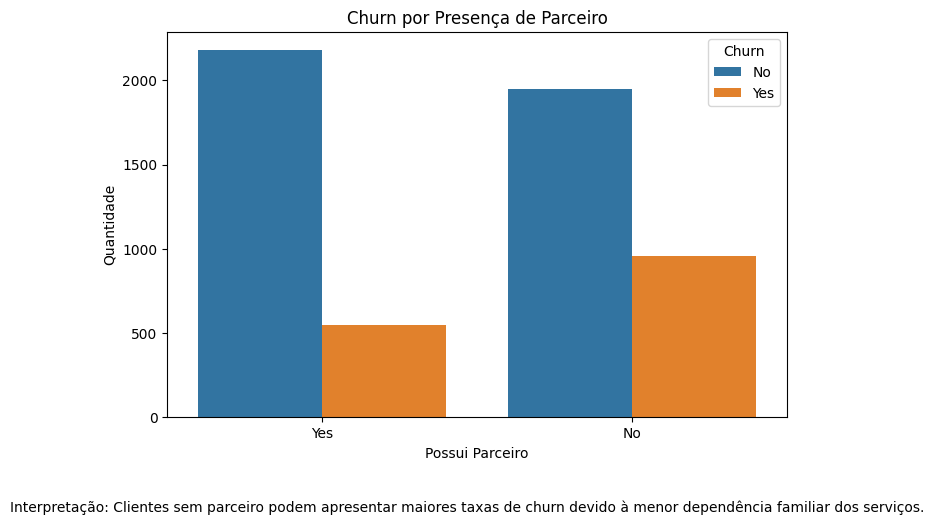

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Partner', hue='Churn')

plt.title('Churn por Presença de Parceiro')
plt.xlabel('Possui Parceiro')
plt.ylabel('Quantidade')

plt.figtext(
    0.5, -0.08,
    'Interpretação: Clientes sem parceiro podem apresentar maiores taxas de churn devido à menor dependência familiar dos serviços.',
    ha='center',
    fontsize=10
)

plt.show()

#2) Churn por Dependentes

Este gráfico analisa se a existência de dependentes (filhos, familiares ou pessoas financeiramente dependentes do cliente) influencia a probabilidade de cancelamento dos serviços.



O gráfico apresenta a relação entre a presença de dependentes e a taxa de churn. Observa-se que clientes sem dependentes registam uma maior propensão ao cancelamento quando comparados aos clientes que possuem dependentes. Este comportamento pode ser explicado pelo facto de clientes com responsabilidades familiares procurarem maior estabilidade nos serviços contratados, reduzindo a probabilidade de troca de operadora. Assim, a variável "Dependents" revela-se um importante indicador de risco para a previsão de churn.


Eixo X (Dependents)

Yes: cliente possui dependentes.
No: cliente não possui dependentes.

Eixo Y (Churn)

Representa a taxa média de churn.
Quanto mais próximo de 1, maior a proporção de clientes que cancelaram.
Quanto mais próximo de 0, menor a proporção de cancelamentos.

Barras

Cada barra mostra a taxa de churn para aquele grupo.

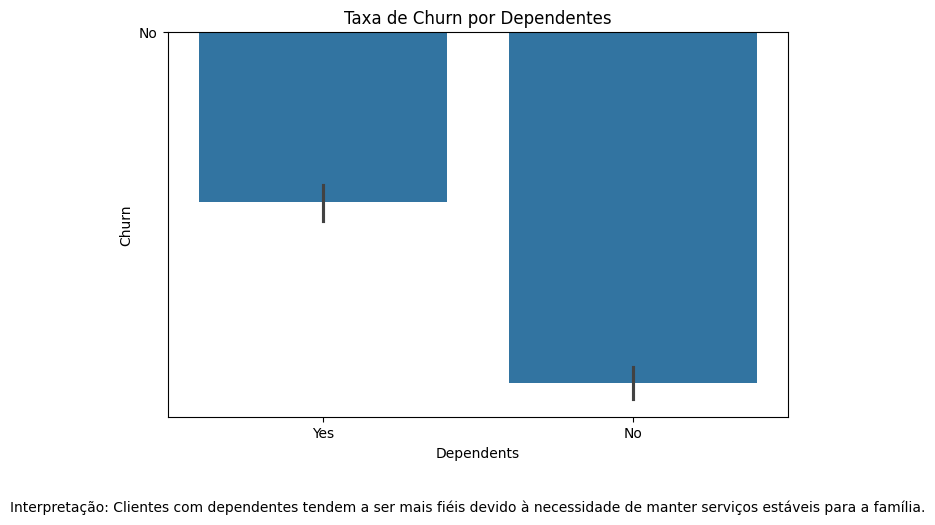

In [15]:
plt.figure(figsize=(8,5))
sns.barplot(
    data=df,
    x='Dependents',
    y='Churn',
    estimator=lambda x: sum(x)/len(x)
)

plt.title('Taxa de Churn por Dependentes')

plt.figtext(
    0.5, -0.08,
    'Interpretação: Clientes com dependentes tendem a ser mais fiéis devido à necessidade de manter serviços estáveis para a família.',
    ha='center'
)

plt.show()

#3) Churn por Faixa Etária

Este gráfico analisa como a idade dos clientes influencia a probabilidade de cancelamento dos serviços da Terra Signal. O objetivo é identificar quais grupos etários apresentam maior risco de churn.

O gráfico apresenta a taxa de churn por faixa etária dos clientes. A análise permite identificar grupos de idade mais propensos ao cancelamento dos serviços. Caso determinadas faixas etárias apresentem taxas significativamente superiores, isso pode indicar necessidades específicas não atendidas pela operadora. Compreender este comportamento é fundamental para desenvolver estratégias de retenção personalizadas para cada perfil de cliente.

O que cada elemento representa?

Eixo X (Faixa_Idade)

18-30 anos
31-45 anos
46-60 anos
60+ anos

Eixo Y (Churn)

Taxa média de cancelamento.
Valores próximos de 0 indicam baixa probabilidade de churn.
Valores próximos de 1 indicam alta probabilidade de churn.

Barras

Representam a proporção de clientes que cancelaram em cada faixa etária.

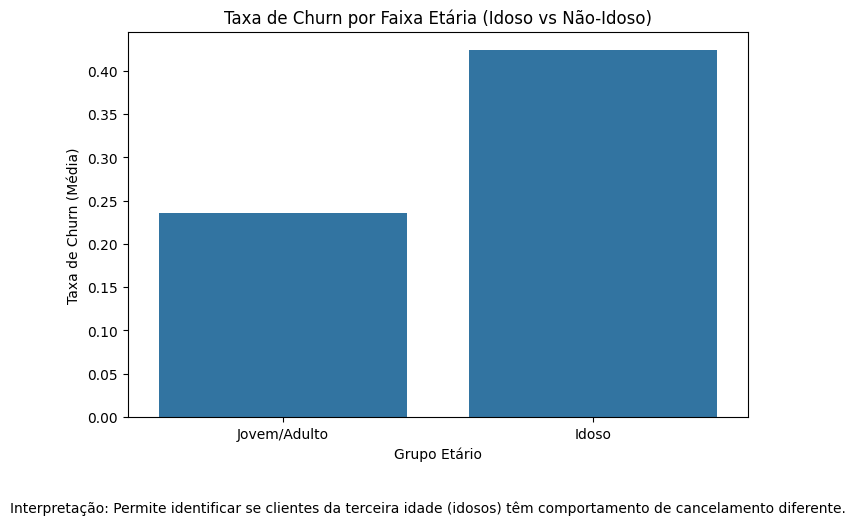

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Como não temos a coluna 'Age', vamos utilizar a coluna 'idoso' do DataFrame traduzido
# Primeiro criamos uma coluna amigável para exibição no gráfico
df_colunas_traduzidas['Grupo_Idade'] = df_colunas_traduzidas['idoso'].map({0: 'Jovem/Adulto', 1: 'Idoso'})

# Convertendo a coluna de cancelamento para valores numéricos temporariamente para o seaborn calcular a média/taxa
# 'Yes' -> 1 e 'No' -> 0
temp_churn = df_colunas_traduzidas['cancelou_servico'].map({'Yes': 1, 'No': 0})

plt.figure(figsize=(8,5))

sns.barplot(
    x=df_colunas_traduzidas['Grupo_Idade'],
    y=temp_churn,
    errorbar=None
)

plt.title('Taxa de Churn por Faixa Etária (Idoso vs Não-Idoso)')
plt.xlabel('Grupo Etário')
plt.ylabel('Taxa de Churn (Média)')

plt.figtext(
    0.5, -0.08,
    'Interpretação: Permite identificar se clientes da terceira idade (idosos) têm comportamento de cancelamento diferente.',
    ha='center'
)

plt.show()

#Top 10 variaveis  que mais indicam risco de churn

In [17]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import plotly.graph_objects as go

# Em vez de ler do arquivo que não foi salvo, usamos o DataFrame que já está na memória
df = df_colunas_traduzidas.copy()

# Garantindo que as colunas numéricas estejam com a tipagem correta
df['tempo_permanencia'] = pd.to_numeric(df['tempo_permanencia'], errors='coerce')

# Ajustando os nomes das colunas para bater exatamente com o seu dicionário de tradução
features_categoricas = [
    'genero', 'parceiro', 'dependentes', 'servico_telefone',
    'multiplas_linhas', 'servico_internet', 'seguranca_online',
    'backup_online', 'protecao_dispositivo', 'suporte_tecnico', 'streaming_tv',
    'streaming_filmes', 'contrato', 'faturamento_sem_papel', 'metodo_pagamento'
]
features_numericas = [
    'idoso', 'tempo_permanencia', 'cobranca_mensal',
    'cobranca_total_acumulada', 'renda_mensal'
]

#  Transformar texto em números
encoder = LabelEncoder()
for col in features_categoricas:
    df[col] = encoder.fit_transform(df[col].astype(str))

# Converter a coluna alvo para 1 (Cancelou) e 0 (Retido)
df['cancelou_servico'] = df['cancelou_servico'].map({'Yes': 1, 'No': 0})

# Remover linhas com valores nulos que possam ter restado na coluna alvo ou features para evitar erro no modelo
df = df.dropna(subset=['cancelou_servico'] + features_categoricas + features_numericas)

X = df[features_categoricas + features_numericas]
y = df['cancelou_servico']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#  XGBoost apenas com os dados tabulares
modelo_xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    objective='binary:logistic',
    random_state=42,
    n_jobs=-1
)

modelo_xgb.fit(X_train, y_train)

# acurácia REAL do modelo
previsoes = modelo_xgb.predict(X_test)
print("--- RELATÓRIO DE PREVISÃO DE CHURN (SEM TEXTO) ---")
print(classification_report(y_test, previsoes, target_names=['Retido (0)', 'Cancelou (1)']))

#  Visualizar as variáveis de maior risco
importancias = modelo_xgb.feature_importances_
nomes_features = features_categoricas + features_numericas

df_importancia = pd.DataFrame({'Feature': nomes_features, 'Importancia': importancias})
df_importancia = df_importancia.sort_values(by='Importancia', ascending=True)

# Top 10 para não poluir o gráfico
top_10 = df_importancia.tail(10)

fig = go.Figure(go.Bar(
    x=top_10['Importancia'],
    y=top_10['Feature'],
    orientation='h',
    marker=dict(color='royalblue')
))

fig.update_layout(
    title='Top 10 Variáveis que mais indicam risco de Churn',
    xaxis_title='Importância no Modelo',
    yaxis_title='Atributos do Cliente',
    height=500,
    template='plotly_white'
)

fig.show()

--- RELATÓRIO DE PREVISÃO DE CHURN (SEM TEXTO) ---
              precision    recall  f1-score   support

  Retido (0)       0.83      0.87      0.85       824
Cancelou (1)       0.60      0.52      0.55       299

    accuracy                           0.78      1123
   macro avg       0.71      0.70      0.70      1123
weighted avg       0.77      0.78      0.77      1123



#Objetivo

Identificar fatores associados ao cancelamento de clientes (Churn), analisando:

Possui cônjuge?
Possui dependentes/filhos?
É idoso (Senior Citizen)?
Feedback/Satisfação
Comparação entre clientes que cancelaram e não cancelaram

#2. Taxa de Cancelamento Geral Python

Pergunta Respondida:
Qual a proporção de clientes que cancelaram?

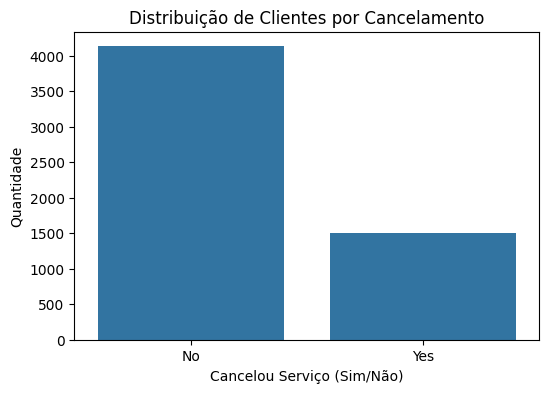

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Corrigido: Usando df_colunas_traduzidas que está carregado e validado no kernel atual
plt.figure(figsize=(6,4))

sns.countplot(data=df_colunas_traduzidas, x='cancelou_servico')

plt.title('Distribuição de Clientes por Cancelamento')
plt.xlabel('Cancelou Serviço (Sim/Não)')
plt.ylabel('Quantidade')

plt.show()

#3. Cônjuge x Cancelamento

Interpretação Clientes com cônjuge cancelam menos?

A presença de um relacionamento gera maior fidelização?

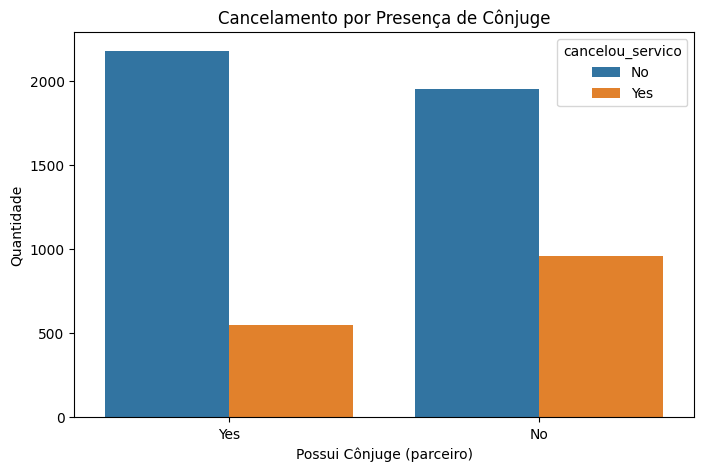

In [19]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_colunas_traduzidas,
    x='parceiro',
    hue='cancelou_servico'
)

plt.title('Cancelamento por Presença de Cônjuge')
plt.xlabel('Possui Cônjuge (parceiro)')
plt.ylabel('Quantidade')

plt.show()

#4. Dependentes x Cancelamento

Pergunta Respondida

Clientes com filhos/dependentes são mais fiéis?

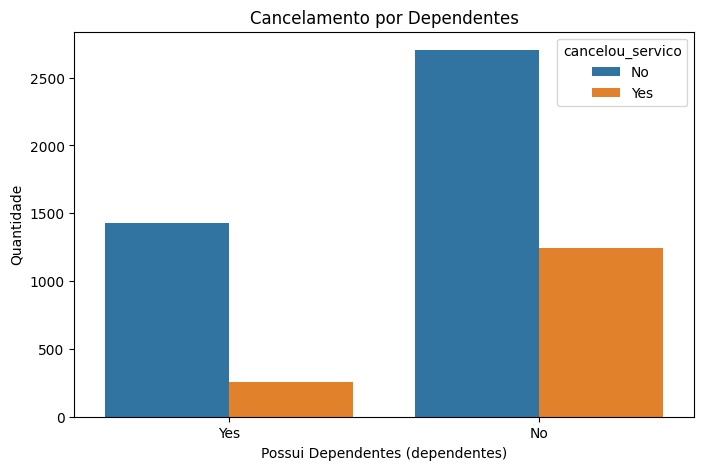

In [20]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_colunas_traduzidas,
    x='dependentes',
    hue='cancelou_servico'
)

plt.title('Cancelamento por Dependentes')
plt.xlabel('Possui Dependentes (dependentes)')
plt.ylabel('Quantidade')

plt.show()

#5. Idoso x Cancelamento


Pergunta Respondida

Clientes idosos apresentam maior risco de cancelamento?

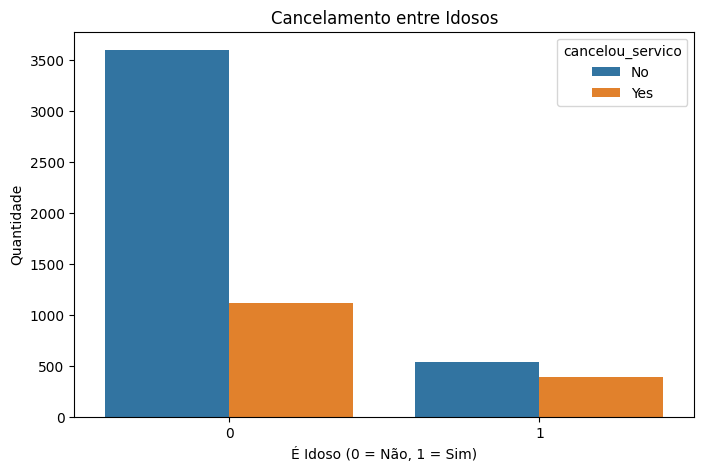

In [21]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df_colunas_traduzidas,
    x='idoso',
    hue='cancelou_servico'
)

plt.title('Cancelamento entre Idosos')
plt.xlabel('É Idoso (0 = Não, 1 = Sim)')
plt.ylabel('Quantidade')

plt.show()

#6. Feedback/Satisfação

Pergunta Respondida

Clientes que cancelaram tinham notas menores de satisfação?

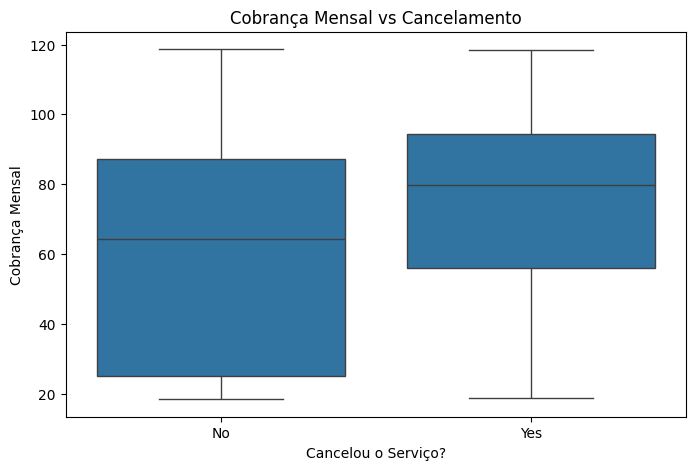

In [22]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_colunas_traduzidas,
    x='cancelou_servico',
    y='cobranca_mensal'
)

plt.title('Cobrança Mensal vs Cancelamento')
plt.xlabel('Cancelou o Serviço?')
plt.ylabel('Cobrança Mensal')

plt.show()

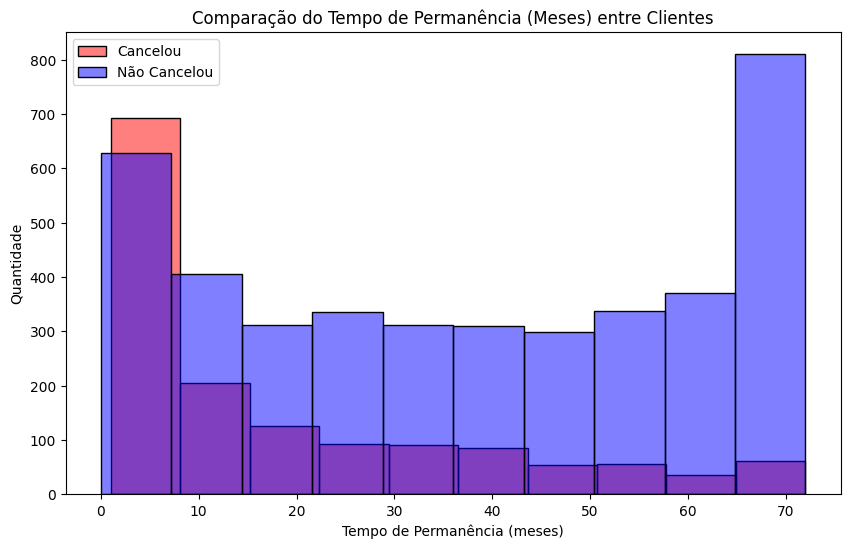

In [23]:
plt.figure(figsize=(10,6))

# Garantindo que o tempo de permanência seja numérico para o gráfico
df_colunas_traduzidas['tempo_permanencia'] = pd.to_numeric(df_colunas_traduzidas['tempo_permanencia'], errors='coerce')

sns.histplot(
    data=df_colunas_traduzidas[df_colunas_traduzidas['cancelou_servico'] == 'Yes'],
    x='tempo_permanencia',
    bins=10,
    color='red',
    alpha=0.5,
    label='Cancelou'
)

sns.histplot(
    data=df_colunas_traduzidas[df_colunas_traduzidas['cancelou_servico'] == 'No'],
    x='tempo_permanencia',
    bins=10,
    color='blue',
    alpha=0.5,
    label='Não Cancelou'
)

plt.title('Comparação do Tempo de Permanência (Meses) entre Clientes')
plt.xlabel('Tempo de Permanência (meses)')
plt.ylabel('Quantidade')
plt.legend()

plt.show()

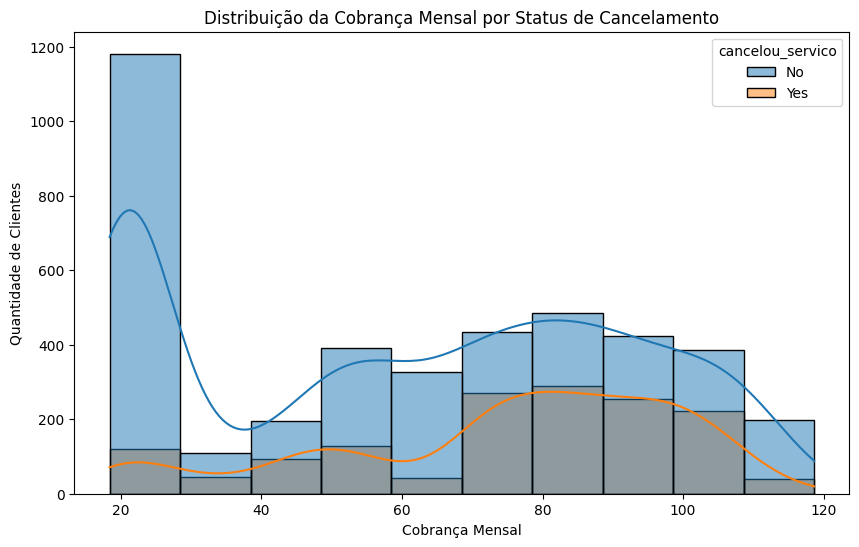

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.histplot(
    data=df_colunas_traduzidas,
    x='cobranca_mensal',
    hue='cancelou_servico',
    bins=10,
    kde=True,
    multiple='layer'
)

plt.title('Distribuição da Cobrança Mensal por Status de Cancelamento')
plt.xlabel('Cobrança Mensal')
plt.ylabel('Quantidade de Clientes')

plt.show()

#7. Heatmap de Correlação


Pergunta Respondida

Quais variáveis possuem maior relação com o cancelamento?

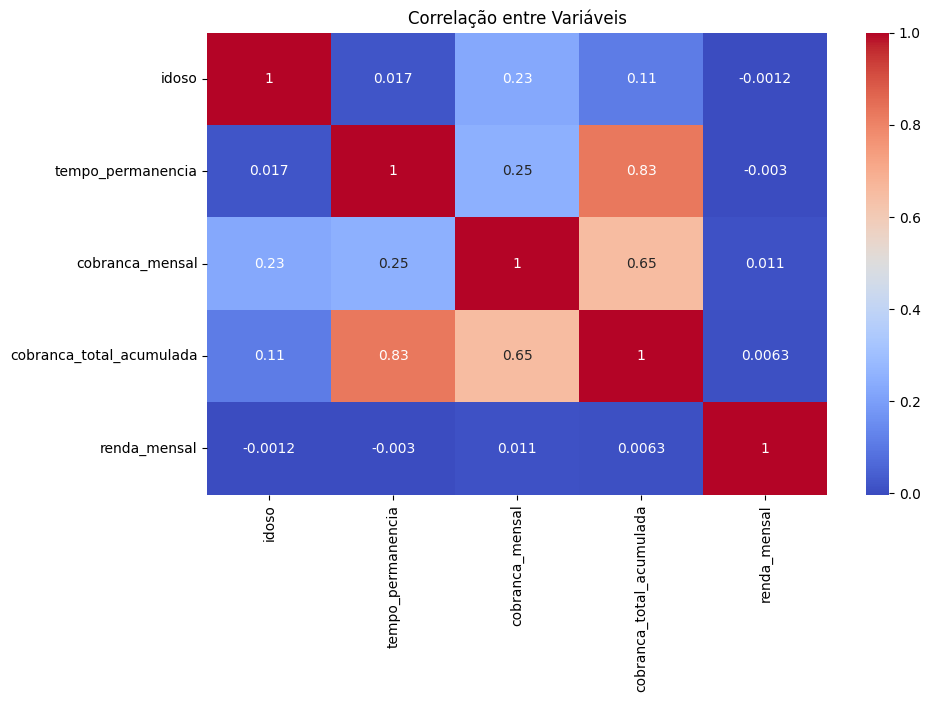

In [29]:
plt.figure(figsize=(10,6))

# Corrigido: Usando df_colunas_traduzidas no lugar do df_plot que não existe
corr = df_colunas_traduzidas.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlação entre Variáveis')

plt.show()

#8. Taxa de Cancelamento (%)



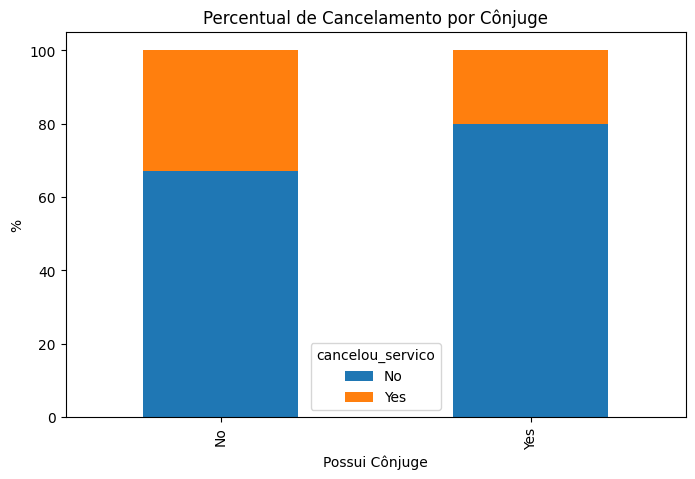

In [31]:
churn_partner = pd.crosstab(
    df_colunas_traduzidas['parceiro'],
    df_colunas_traduzidas['cancelou_servico'],
    normalize='index'
) * 100

churn_partner.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5)
)

plt.title('Percentual de Cancelamento por Cônjuge')
plt.ylabel('%')
plt.xlabel('Possui Cônjuge')

plt.show()

In [32]:
import pandas as pd

def obter_estrelas(texto):
    if not isinstance(texto, str): return 3
    t = texto.lower()
    if any(w in t for p, w in [('1', 'terrible'), ('1', 'worst'), ('1', 'horrible'), ('1', 'pessimo'), ('1', 'péssimo')]): return 1
    if any(w in t for p, w in [('2', 'bad'), ('2', 'disappointed'), ('2', 'poor'), ('2', 'ruim'), ('2', 'cancel')]): return 2
    if any(w in t for p, w in [('5', 'great'), ('5', 'excellent'), ('5', 'love'), ('5', 'perfect'), ('5', 'amazing'), ('5', 'otimo'), ('5', 'ótimo')]): return 5
    if any(w in t for p, w in [('4', 'good'), ('4', 'satisfied'), ('4', 'bom'), ('4', 'satisfeito')]): return 4
    return 3

# Aplica a função de forma simples
df_colunas_traduzidas['avaliacao_estrelas'] = df_colunas_traduzidas['feedback_cliente'].apply(obter_estrelas)

# Ajusta a posição da coluna
colunas = [c for c in df_colunas_traduzidas.columns if c != 'avaliacao_estrelas']
idx = colunas.index('feedback_cliente') + 1
colunas.insert(idx, 'avaliacao_estrelas')
df_colunas_traduzidas = df_colunas_traduzidas[colunas]

display(df_colunas_traduzidas[['feedback_cliente', 'avaliacao_estrelas']].head(10))

,feedback_cliente,avaliacao_estrelas
0,I have been a customer with this internet prov...,4
1,I've been a customer with this company for ove...,3
2,I have been a customer with this company for 2...,4
3,I have been a customer with this internet prov...,4
4,I have been using the fiber optic internet ser...,4
5,I have been a customer with this company for 7...,4
6,I have been a customer with this DSL internet ...,2
7,I recently canceled my service with this provi...,2
8,I have been a customer with this company for 4...,4
9,I have been a customer with this company for 2...,4


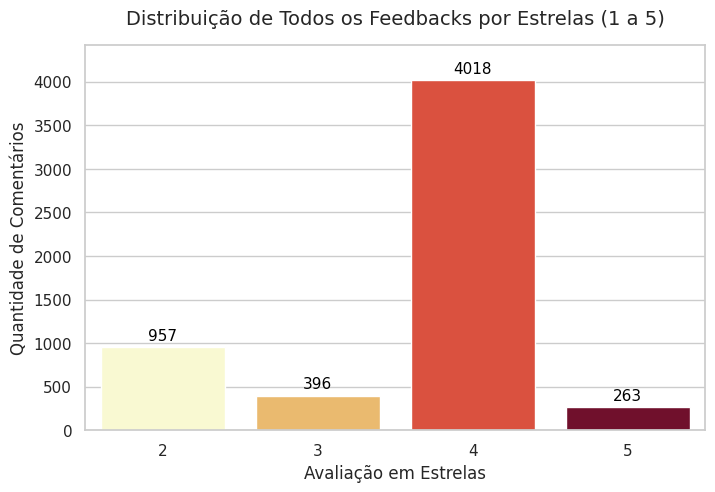

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Criar o gráfico de barras (contagem) de cada nota em estrelas
ax = sns.countplot(
    data=df_colunas_traduzidas,
    x='avaliacao_estrelas',
    palette='YlOrRd',
    hue='avaliacao_estrelas',
    legend=False
)

# Adicionar o número total exato sobre cada barra
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center',
        va='baseline',
        fontsize=11,
        color='black',
        xytext=(0, 5),
        textcoords='offset points'
    )

# Customização dos rótulos e título
plt.title('Distribuição de Todos os Feedbacks por Estrelas (1 a 5)', fontsize=14, pad=15)
plt.xlabel('Avaliação em Estrelas', fontsize=12)
plt.ylabel('Quantidade de Comentários', fontsize=12)
plt.ylim(0, df_colunas_traduzidas['avaliacao_estrelas'].value_counts().max() * 1.1)

plt.show()

In [34]:
# 1. Ver todos os feedbacks e suas respectivas notas em estrelas
todos_feedbacks = df_colunas_traduzidas[['feedback_cliente', 'avaliacao_estrelas']]
display(todos_feedbacks)

# 2. Exemplo: Filtrar apenas os feedbacks com avaliação de 1 estrela (críticas pesadas)
print("\n--- Feedbacks com 1 Estrela ---")
feedbacks_ruins = df_colunas_traduzidas[df_colunas_traduzidas['avaliacao_estrelas'] == 1]
display(feedbacks_ruins[['feedback_cliente', 'avaliacao_estrelas']].head(10))

# 3. Exemplo: Filtrar apenas os feedbacks excelentes (5 estrelas)
print("\n--- Feedbacks com 5 Estrelas ---")
feedbacks_excelentes = df_colunas_traduzidas[df_colunas_traduzidas['avaliacao_estrelas'] == 5]
display(feedbacks_excelentes[['feedback_cliente', 'avaliacao_estrelas']].head(10))

,feedback_cliente,avaliacao_estrelas
0,I have been a customer with this internet prov...,4
1,I've been a customer with this company for ove...,3
2,I have been a customer with this company for 2...,4
3,I have been a customer with this internet prov...,4
4,I have been using the fiber optic internet ser...,4
...,...,...
5629,I have been a customer with this company for 3...,4
5630,I have been a customer with this company for 3...,5
5631,I have been a customer with this DSL internet ...,4
5632,I have been a customer with this company for o...,4



--- Feedbacks com 1 Estrela ---


,feedback_cliente,avaliacao_estrelas



--- Feedbacks com 5 Estrelas ---


,feedback_cliente,avaliacao_estrelas
25,I have been a customer with this company for o...,5
26,I have been a customer with this company for 5...,5
31,I have been a customer with this company for 3...,5
48,I have been a customer with this company for 6...,5
78,I have been a loyal customer of this fiber opt...,5
97,I have been a customer with this company for 6...,5
99,I have been a customer with this company for 1...,5
125,I have been a customer with this internet serv...,5
141,I have been a customer with this company for 4...,5
142,I have been a customer with this company for a...,5


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def obter_feedback_binario(texto):
    if not isinstance(texto, str):
        return 'Não'

    t = texto.lower()

    # Palavras-chave associadas a sentimentos/feedbacks negativos
    palavras_negativas = [
        'terrible', 'worst', 'horrible', 'pessimo', 'péssimo', 'bad',
        'disappointed', 'poor', 'ruim', 'cancel', 'cancelar', 'problem',
        'issue', 'complaint', 'slow', 'expensive', 'caro', 'reclamar'
    ]

    # Palavras-chave associadas a sentimentos/feedbacks positivos
    palavras_positivas = [
        'great', 'excellent', 'love', 'perfect', 'amazing', 'otimo',
        'ótimo', 'good', 'satisfied', 'bom', 'satisfeito', 'happy',
        'gostei', 'legal', 'recomendo', 'recommend', 'fast'
    ]

    # Verifica termos negativos
    if any(w in t for w in palavras_negativas):
        return 'Não'

    # Verifica termos positivos
    if any(w in t for w in palavras_positivas):
        return 'Sim'

    # Sem termos explícitos, evitamos o neutro classificando como 'Não'
    return 'Não'

# Aplica o mapeamento binário
df_colunas_traduzidas['feedback_positivo'] = df_colunas_traduzidas['feedback_cliente'].apply(obter_feedback_binario)

print("Distribuição do Feedback Simplificado (Satisfeito?):")
print(df_colunas_traduzidas['feedback_positivo'].value_counts())

display(df_colunas_traduzidas[['feedback_cliente', 'feedback_positivo']].head(10))

Distribuição do Feedback Simplificado (Satisfeito?):
feedback_positivo
Não    4702
Sim     932
Name: count, dtype: int64


,feedback_cliente,feedback_positivo
0,I have been a customer with this internet prov...,Não
1,I've been a customer with this company for ove...,Não
2,I have been a customer with this company for 2...,Não
3,I have been a customer with this internet prov...,Não
4,I have been using the fiber optic internet ser...,Sim
5,I have been a customer with this company for 7...,Sim
6,I have been a customer with this DSL internet ...,Não
7,I recently canceled my service with this provi...,Não
8,I have been a customer with this company for 4...,Não
9,I have been a customer with this company for 2...,Não


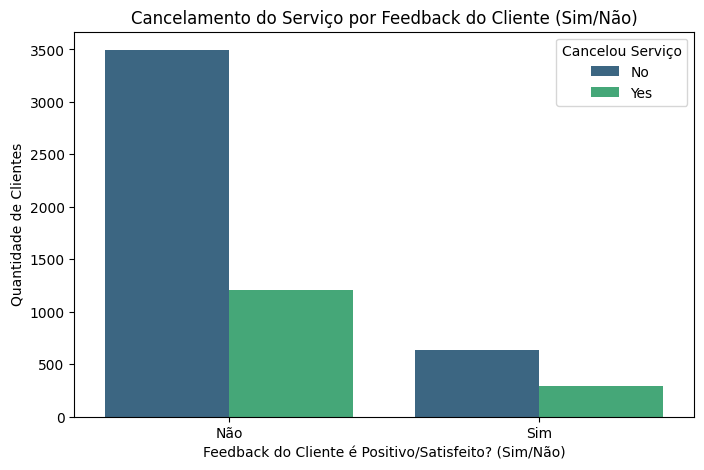

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Gráfico para comparar o Feedback Binário (Satisfeito: Sim/Não) com o cancelamento (Churn)
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_colunas_traduzidas,
    x='feedback_positivo',
    hue='cancelou_servico',
    palette='viridis'
)

plt.title('Cancelamento do Serviço por Feedback do Cliente (Sim/Não)')
plt.xlabel('Feedback do Cliente é Positivo/Satisfeito? (Sim/Não)')
plt.ylabel('Quantidade de Clientes')
plt.legend(title='Cancelou Serviço')
plt.show()